In [ ]:
# ============================================================
# 0-1. 구글 드라이브 마운트
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/kaggle-learn/secom'


Mounted at /content/drive


In [2]:
# ============================================================
# 0-2. 원본 데이터 불러오기
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X = pd.read_csv(f'{DATA_DIR}/secom.data', sep=r'\s+', header=None)
print(X.shape[1])
print()
X.columns = [f'sensor_{i:03d}' for i in range(X.shape[1])]

y = pd.read_csv(f'{DATA_DIR}/secom_labels.data', sep='\s+', header=None, names=['label','timestamp'])

target = (y['label'] == 1).astype(int) # 불합격 = 1, 합격 = 0

print(X.shape, '/불합격 비율:', round(target.mean(), 3))


<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_144/1602511886.py:13: SyntaxWarning: invalid escape sequence '\s'
  y = pd.read_csv(f'{DATA_DIR}/secom_labels.data', sep='\s+', header=None, names=['label','timestamp'])


590

(1567, 590) /불합격 비율: 0.066


In [3]:
# ============================================================
# 1. 결측치가 얼마나 있나? — [DC-1]
# ============================================================
total_cells = np.prod(X.shape)
total_missing = X.isnull().sum().sum()
# .1% 백분율(%)로 변환하고, 소수점 첫째 자리까지 표시
print(f'전체 { total_cells:,}칸 중 결측 {total_missing:,}칸 ({total_missing / total_cells:.1%})')

print('결측치가 하나라도 있는 행(제품):', X.isnull().any(axis=1).sum(), '/', len(X))
print('결측치가 하나라도 있는 열(센서):', X.isnull().any(axis=0).sum(), '/', X.shape[1])

전체 924,530칸 중 결측 41,951칸 (4.5%)
결측치가 하나라도 있는 행(제품): 1567 / 1567
결측치가 하나라도 있는 열(센서): 538 / 590


In [4]:
# ============================================================
# 2. 방법 ① 행(제품) 삭제 — [DC-1] dropna()
# ============================================================
rows_dropped = X.dropna(axis=0)
print('행 삭제 후 : ', rows_dropped.shape)

'''
axis=0 → 세로 방향(↓), 각 열을 따라 계산
axis=1 → 가로 방향(→), 각 행을 따라 계산

axis=0은 행 축, axis=1은 열 축을 의미합니다

'''

행 삭제 후 :  (0, 590)


'\naxis=0 → 세로 방향(↓), 각 열을 따라 계산\naxis=1 → 가로 방향(→), 각 행을 따라 계산\n\naxis=0은 행 축, axis=1은 열 축을 의미합니다\n\n'

In [5]:
# ============================================================
# 3. 방법 ② 열(센서) 삭제 — [DC-1] dropna(axis=1)
# ============================================================
cols_dropped = X.dropna(axis=1)

print('열 삭제 후 :', cols_dropped.shape)
print(f'남은 센서: {cols_dropped.shape[1]}개 / 원래 {X.shape[1]}개 → {1 - cols_dropped.shape[1] / X.shape[1]:.0%} 버림')

열 삭제 후 : (1567, 52)
남은 센서: 52개 / 원래 590개 → 91% 버림


In [6]:
# ============================================================
# 4. 방법 ③ 0으로 채우기 — [DC-1] fillna(0)
# ============================================================
X_zero = X.fillna(0)

# sensor_000은 원래 값이 2,743 ~ 3,356 사이인 센서
col = 'sensor_000'
print('원래 범위:', X[col].min(), '~', X[col].max(), '/ 결측', X[col].isnull().sum(), '개')
print('0으로 채운 뒤 최솟값:', X_zero[col].min())
print('평균 변화:', round(X[col].mean(), 1), '→', round(X_zero[col].mean(), 1))

원래 범위: 2743.24 ~ 3356.35 / 결측 6 개
0으로 채운 뒤 최솟값: 0.0
평균 변화: 3014.5 → 3002.9


In [7]:
# ============================================================
# 5. 방법 ④ 앞뒤 값으로 채우기 — [DC-1] ffill() / bfill()
#    (레슨의 fillna(method='bfill')은 최신 pandas에서 경고가 나서 bfill()을 바로 씀)
# ============================================================

X_ffill = X.ffill().bfill()
print('남은 결측치:', int(X_ffill.isnull().sum(axis=0).sum(axis=0)))
print()
print()

# 예시 : 결측이 있는 행 하나를 앞뒤 행과 함께 보기
col = 'sensor_000'

# 특정 열(col)에 결측치(NaN)가 있는 행을 찾고, 그중 첫 번째 행의 인덱스를 가져오는 코드
idx = X[X[col].isnull()].index[0]
print(idx)
print(pd.DataFrame({'원래': X[col].iloc[idx-1:idx+2], 'ffill 후': X_ffill[col].iloc[idx-1:idx+2]}))

남은 결측치: 0


21
         원래  ffill 후
20  2987.32  2987.32
21      NaN  2987.32
22  3002.27  3002.27


In [8]:
# ============================================================
# 6. 방법 ⑤ 중앙값 채우기, 방법 ⑥ 중앙값 + 결측 표시 — [DC-1] / [IML] Missing Values
# ============================================================
from sklearn.impute import SimpleImputer
'''
SimpleImputer : 결측치를 다른 값으로 대체하는 클래스
fit_transform() : 머신러닝에서 데이터의 특징을 학습하고(fit)하고, 그 결과를 이용해 데이터를
변환(transform)하는 작업을 한 번에 수행하는 메서드이다.

fir() : 데이터에서 필요한 정보를 학습
transform() : 학습한 정보를 이용해 데이터를 변환
fit_transform() : 학습과 변환을 동시에 수행

'''


imp = SimpleImputer(strategy='median')
X_median = pd.DataFrame(imp.fit_transform(X), columns=X.columns)
print('중앙값 채우기 후 결측치 : ', int(X_median.isnull().sum().sum()))
print()
print()

# add_indicator : SimpleImputer에서 원래 결측치(NaN)가 있었던 위치를 표시하는 열을 추가할지 결정하는 옵션
imp_ind = SimpleImputer(strategy='median', add_indicator=True)
X_median_ind = imp_ind.fit_transform(X)
print('결측 표시 추가 후 열 개수 :', X_median_ind.shape[1], '(센서 590 + 결측 표시 열)')
print()
print()

중앙값 채우기 후 결측치 :  0


결측 표시 추가 후 열 개수 : 1128 (센서 590 + 결측 표시 열)




In [9]:
# ============================================================
# 7. 어느 방법이 좋은가? 모델 점수로 비교 — [IML] Missing Values, Pipelines 미리보기
#    ⏱ 코랩에서 1~2분
# ============================================================
from sklearn.model_selection import StratifiedKFold, cross_val_score
'''
StratifiedKFold :데이터를 어떤 방식으로 나눌 지 결정한다.
cross_val_score : 나눈 데이터를 이용해 모델을 반복 학습하고 성능 점수를 계산한다.

1. 교차 검증(Cross Validation)란?
머신러닝 모델을 평가할 때 데이터를 학습용(Train)과 검증용(Validation)으로 나눈다.
하지만 한 번만 나누면 어떤 데이터가 검증용으로 선택되었는지에 따라 성능이 달라질 수 있다.
그래서 데이터를 여러 번 다르게 나누어 평가하는 것이 교차 검증이다.

2. StratifiedKFold란?
StratifiedKFold는 클래스의 비율을 최대한 유지하면서 데이터를 K개로 나누는 교차 검증 기법이다.

'''
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier


# StratifiedKFold는 정답 데이터 y를 확인한 후 각 조각의 클래스 비율이 전체 비율과
# 최대한 비슷하도록 나눈다.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


'''
RandomForestClassifier:
분류 모델을 생성하고, 학습에 사용할 설정을 지정하는 코드이다.
100개의 의사결정 나무를 만들어 각각 예측하게 한 뒤, 다수결로 최종 결과를 결정하는 모델이다.

n_estimators : 의사결정나무 100개생성
class_weight : 클래스 불균형을 고려해 가중치 설정
min_samples_leaf : 말단 노드에 최소 3개의 학습 샘플 필요 -> 과적합 방지(최소 3개의 샘플이 있어야 하므로 지나치게 세밀한 분할을 제한)
random_state : 난수 시드 고정으로 결과 재현
n_jobs : 사용 가능한 모든 CPU 코어 활용

'''

def rf():
  return RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', min_samples_leaf=3, random_state=42, n_jobs=-1)


missing_ratio = X.isnull().mean()
keep_cols = missing_ratio[missing_ratio < 0.5].index
# print(keep_cols)


methods = {
    '② 열 삭제 (결측 있는 센서 전부)' : (X.dropna(axis=1), make_pipeline(rf())),
    '③ 0으로 채우기':                 (X.fillna(0),         make_pipeline(rf())),
    '④ 앞뒤 값으로 채우기':           (X.ffill().bfill(),   make_pipeline(rf())),
    '⑤ 중앙값 채우기':                (X,                   make_pipeline(SimpleImputer(strategy='median'), rf())),
    '⑥ 중앙값 + 결측 표시':           (X,                   make_pipeline(SimpleImputer(strategy='median', add_indicator=True), rf())),
    '실습1: 50% 초과 삭제 + 중앙값':   (X[keep_cols],        make_pipeline(SimpleImputer(strategy='median'), rf())),
}

rows = []

for name, (data, model) in methods.items():
    scores = cross_val_score(model, data, target, cv=cv, scoring='roc_auc')
    rows.append({'방법': name, '센서 수': data.shape[1],
                 'AUC 평균': round(scores.mean(), 3), 'AUC 흔들림(표준편차)': round(scores.std(), 3)})


missing_result = pd.DataFrame(rows).sort_values('AUC 평균', ascending=False)
missing_result

,방법,센서 수,AUC 평균,AUC 흔들림(표준편차)
4,⑥ 중앙값 + 결측 표시,590,0.723,0.033
2,④ 앞뒤 값으로 채우기,590,0.714,0.039
5,실습1: 50% 초과 삭제 + 중앙값,562,0.712,0.026
3,⑤ 중앙값 채우기,590,0.700,0.051
1,③ 0으로 채우기,590,0.690,0.029
0,② 열 삭제 (결측 있는 센서 전부),52,0.527,0.052


결측치 처리 방법 6가지를 직접 적용해 본 뒤, 똑같은 랜덤 포레스트로 5겹 교차검증 점수를 매겨 어떤 처리 방법이 불량 예측에 가장 도움이 되는지 비교한다.

In [10]:
# ============================================================
# Part 2 준비: 실습 1 방식으로 정리한 센서만 사용
# ============================================================
Xs = X[keep_cols]
print(Xs.nunique()) # Pandas에서 각 열(Column)에 서로 다른 값이 몇 개 있는지 세는 메서드이다.

Xs = Xs.loc[:, Xs.nunique() > 1] # 값이 하나 뿐인 센서 제거
# print(Xs)


sensor_000    1520
sensor_001    1504
sensor_002     507
sensor_003     518
sensor_004     503
              ... 
sensor_585    1502
sensor_586     322
sensor_587     260
sensor_588     120
sensor_589     611
Length: 562, dtype: int64


In [11]:
# ============================================================
# 8. 왜 스케일링이 필요한가? 센서마다 숫자 범위가 다르다 — [DC-2]
# ============================================================

desc = Xs.describe().T[['min', 'max', 'std']]
# print(desc)
print()
print()


# 범위가 작은 센서부터 큰 센서까지 몇 개 뽑아보기
# iloc[[-1]] : 마지막 행
sample = desc.sort_values('max').iloc[[1, 100, 200, 300, 400, -1]]
print(sample.round(4))
print()
print()

ranges = desc['max'] - desc['min']
print(f"\n가장 센서가 넓은 범위 / 가장 센서가 좁은 범위 = {ranges.max() / ranges[ranges > 0].min():,.0f}배")





               min         max        std
sensor_095 -0.0009      0.0009     0.0001
sensor_171  0.0089      0.4940     0.0608
sensor_549  0.0446      7.0656     0.6733
sensor_428  1.1198    118.7533    10.6327
sensor_489  0.0000    994.0035   228.0467
sensor_161  0.0000  37943.0000  4239.2451



가장 센서가 넓은 범위 / 가장 센서가 좁은 범위 = 21,079,444배


In [12]:
# ============================================================
# 9-1. 스케일링 3종류 비교 (sensor_059) — [DC-2] MinMax / Standard / Robust
# ============================================================
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
'''
MinMaxScaler : 최솟값을 0, 최댓값을 1로!
StandardScaler : 평균을 0, 표준편차를 1로!
RobustScaler : 중앙값을 0으로, IQR을 기준으로!

'''

col = 'sensor_059'
v = Xs[[col]].fillna(Xs[col].median())
print(v)
print()
print()

'''
ravel() : numpy에서 다차원 배열을 1차원 배열로 펼쳐주는 메서드
스케일링한 결과를 DataFrame의 한 열에 저장하기 위한 형태 변환 함수
'''
scaled = pd.DataFrame({
    'Original' : v[col],
    'MinMax' : MinMaxScaler().fit_transform(v).ravel(),
    'Standard' : StandardScaler().fit_transform(v).ravel(),
    'Robust' : RobustScaler().fit_transform(v).ravel()
})
print(scaled.describe().round(3))

      sensor_059
0        -1.7264
1         0.8073
2        23.8245
3        24.3791
4       -12.2945
...          ...
1562      2.8182
1563     -3.3555
1564      1.1664
1565      4.4682
1566      1.8718

[1567 rows x 1 columns]


       Original    MinMax  Standard    Robust
count  1567.000  1567.000  1567.000  1567.000
mean      2.951     0.162     0.000     0.324
std       9.512     0.048     1.000     1.536
min     -28.988     0.000    -3.359    -4.834
25%      -1.855     0.138    -0.505    -0.453
50%       0.947     0.152    -0.211     0.000
75%       4.338     0.169     0.146     0.547
max     168.146     1.000    17.373    26.997


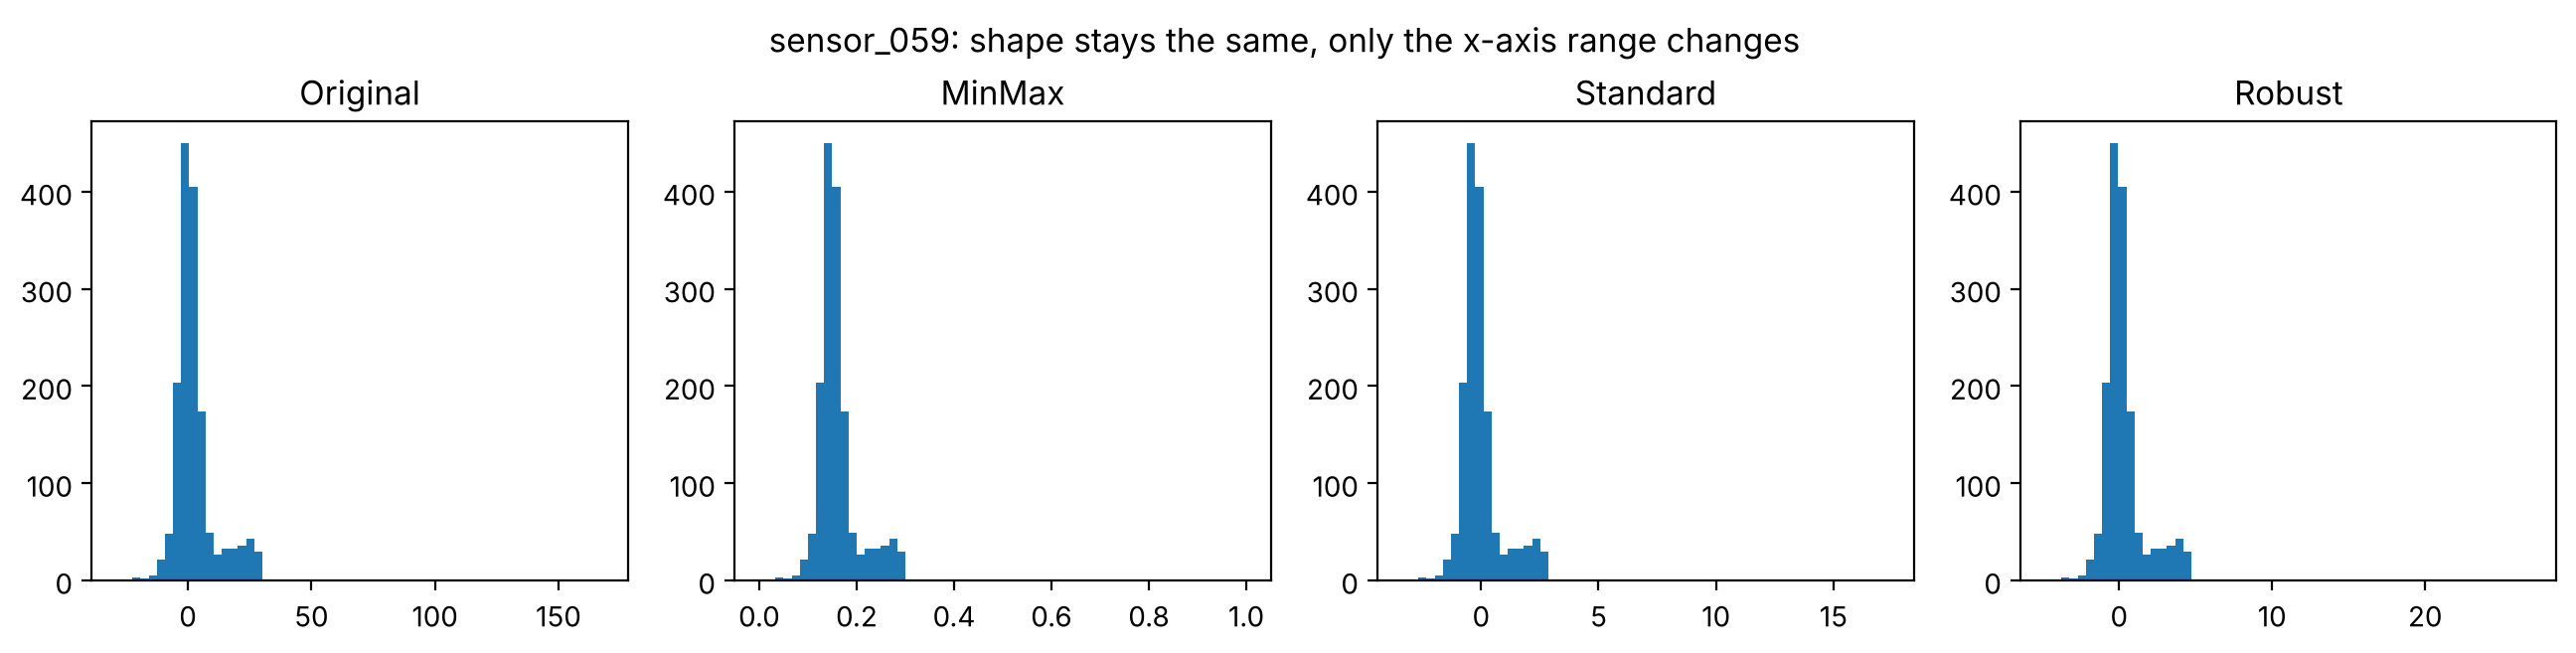

In [13]:
# ============================================================
# 9-2. 스케일링 전후 그래프 (모양은 그대로, x축 범위만 바뀜)
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, name in zip(axes, scaled.columns):
    ax.hist(scaled[name], bins=60)
    ax.set_title(name)
plt.suptitle('sensor_059: shape stays the same, only the x-axis range changes', y=1.05)
plt.show()

### 📌 9-2 결과 해석 — 범위가 가장 작은 걸 고르는 게 아니다

**① 스케일링은 그래프 모양을 바꾸지 않는다.** 4개 그래프의 모양이 똑같고 x축 숫자만 다르다. 스케일링은 **단위만 바꾸는 것**이고, 쏠림이나 튀는 값은 그대로 남는다.

**② MinMax는 튀는 값이 있으면 데이터를 찌그러뜨린다.** 범위가 0\~1로 가장 작지만, sensor\_059의 최댓값 168 하나가 그 범위를 대부분 차지한다. 그래서 제품의 가운데 절반이 **0.14\~0.17**이라는 아주 좁은 구간에 몰린다. 제품끼리의 차이가 작은 숫자로 눌려 버린 것이다.

**그럼 무엇으로 고르나?**
1. **모델**: 트리 모델(RF, XGBoost)이면 스케일링 자체가 필요 없다.
2. **튀는 값**: 있으면 MinMax보다 Standard나 Robust가 안전하다.
3. 마지막 판단은 그래프가 아니라 **11장처럼 점수로 비교**해서 한다.

In [14]:
# ============================================================
# 10-1. 정규화: 치우친 분포 펴기 — [DC-2] Box-Cox / Yeo-Johnson
# ============================================================
from scipy import stats
from sklearn.preprocessing import PowerTransformer
'''
PowerTransformer : 데이터의 분포를 변환
method='box-cox' : 양수 데이터의 분포 변환
method='yeo-johnson' : 양수/0/음수 데이터의 분포 변환
.to_frame() : Sereis -> DataFrame
.ravel() : 다차원 -> 1차원 배열

'''

skews = Xs.apply(lambda c : stats.skew(c.dropna()))
print('많이 쏠린 센서(|왜도| > 2):', (skews.abs() > 2).sum(), '/', Xs.shape[1])

# (1) Box-Cox : 양수만 있는 센서 중 가장 쏠린 것
pos_cols = Xs.columns[Xs.min() > 0]
bc_col = skews[pos_cols].abs().idxmax()
bc_before = Xs[bc_col].dropna()
bc_after, lam = stats.boxcox(bc_before)
print(f'''
[Box-cox] {bc_col} : 왜도 {stats.skew(bc_before):.2f} → {stats.skew(bc_after):.2f}')

''')


# (2) Yeo-Johnson : 음수가 있는 sensor_059
yj_before = Xs['sensor_059'].dropna()
yj_after = PowerTransformer(method='yeo-johnson').fit_transform(yj_before.to_frame()).ravel()
print(f'[Yeo-Johnson] sensor_059: 왜도 {stats.skew(yj_before):.2f} → {stats.skew(yj_after):.2f}')

많이 쏠린 센서(|왜도| > 2): 248 / 446

[Box-cox] sensor_390 : 왜도 39.52 → -0.17')


[Yeo-Johnson] sensor_059: 왜도 4.71 → -0.13


### 📌 10-1 결과 해석 — 센서의 절반 이상이 심하게 쏠려 있고, 정규화로 펼 수 있다

| 출력 | 뜻 |
|---|---|
| 많이 쏠린 센서 **248 / 446** | 센서의 56%가 한쪽으로 심하게 치우침 (왜도 절댓값 2 초과) |
| Box-Cox sensor\_390: 왜도 **39.52 → -0.17** | 극단적으로 쏠린 센서가 거의 대칭이 됨 |
| Yeo-Johnson sensor\_059: 왜도 **4.71 → -0.13** | 음수가 있는 센서도 거의 대칭이 됨 |

- **왜도**: 0이면 좌우 대칭, 절댓값이 클수록 한쪽으로 쏠림.
- **Box-Cox는 0보다 큰 값만** 처리할 수 있어서 양수만 있는 sensor\_390에 썼다.
- sensor\_059처럼 **음수가 있으면 Yeo-Johnson**을 쓴다. 센서 데이터에는 음수가 흔하므로 실제로는 Yeo-Johnson(`PowerTransformer`)을 주로 쓴다.

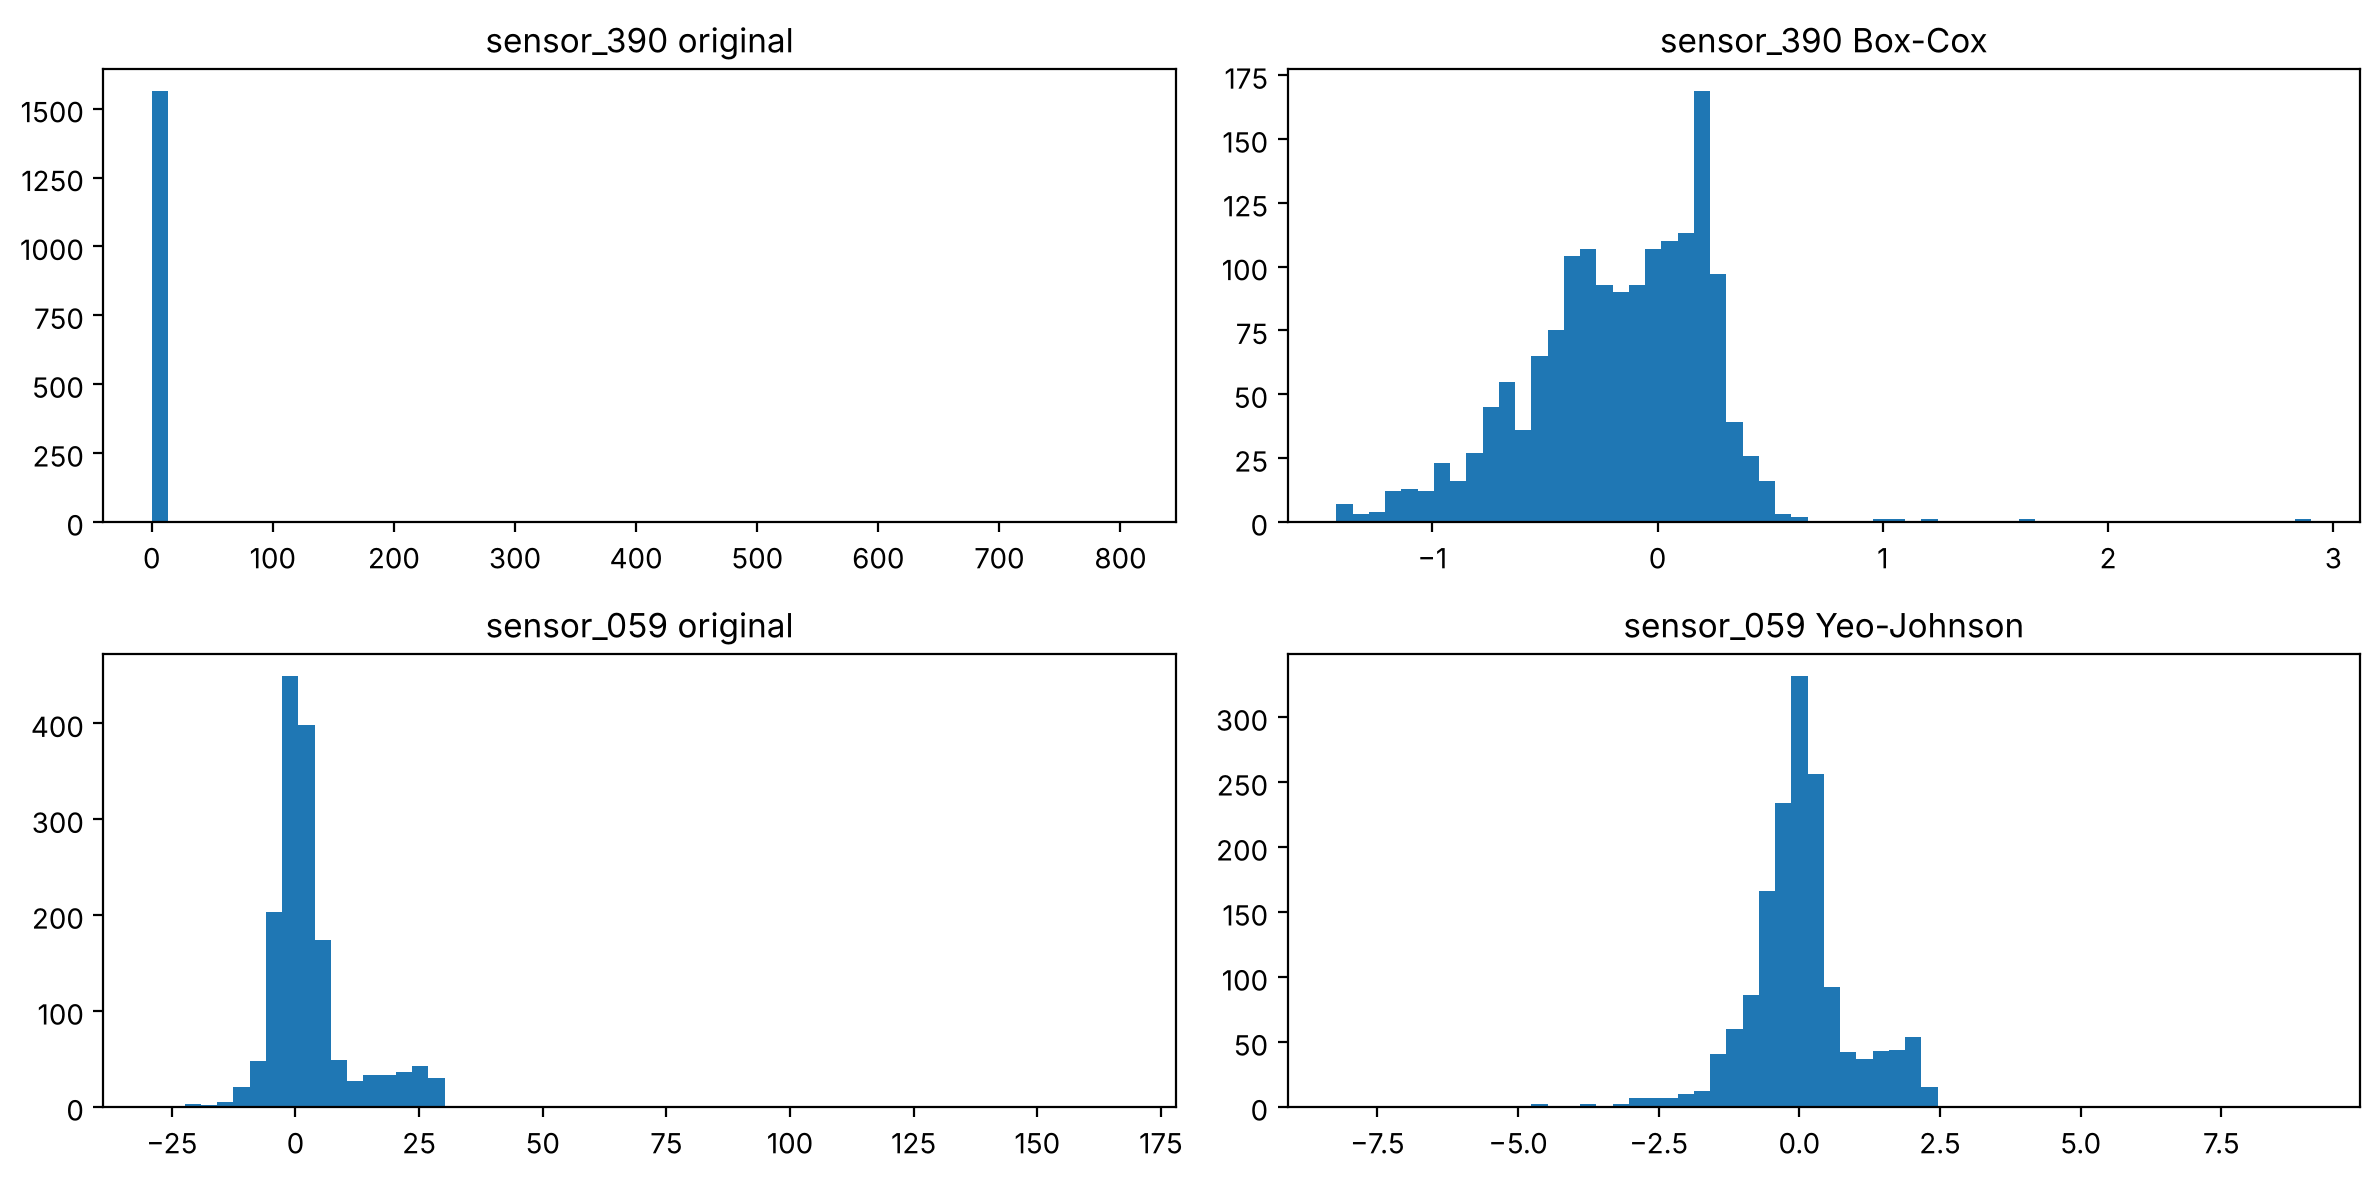

In [15]:
# ============================================================
# 10-2. 정규화 전후 그래프 (모양 자체가 종 모양에 가깝게 바뀜)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12,6))
axes[0, 0].hist(bc_before, bins=60); axes[0, 0].set_title(f'{bc_col} original')
axes[0, 1].hist(bc_after, bins=60);  axes[0, 1].set_title(f'{bc_col} Box-Cox')
axes[1, 0].hist(yj_before, bins=60); axes[1, 0].set_title('sensor_059 original')
axes[1, 1].hist(yj_after, bins=60);  axes[1, 1].set_title('sensor_059 Yeo-Johnson')

plt.tight_layout()
plt.show()

### 📌 10-2 결과 해석 — 정규화는 그래프 모양 자체를 바꾼다

- **sensor\_390 원본**: 0 근처에 막대 하나만 보인다. 1,567개 중 1,566개가 0.3\~10 사이인데, **단 1개가 805**라서 x축이 0\~800으로 늘어났기 때문이다. 나머지 값이 전부 맨 왼쪽 막대에 묻혔다.
- **sensor\_390 Box-Cox 후**: 넓게 퍼진 산 모양이 되어, 묻혀 있던 **제품 간 차이가 보이게** 됐다.
- **sensor\_059**: 오른쪽으로 길게 늘어진 꼬리가 0을 중심으로 좌우가 비슷한 모양이 됐다.

| | 9-2 스케일링 | 10-2 정규화 |
|---|---|---|
| 그래프 모양 | 그대로 | **바뀜** (쏠림이 펴짐) |
| 바뀌는 것 | x축 숫자(단위)만 | 값들 사이의 간격 |
| 튀는 값 | 그대로 남음 | 영향이 크게 줄어듦 |

→ 정말 모델에 도움이 되는지는 **11-1**에서 점수로 확인한다.

In [16]:
# ============================================================
# 11. 스케일링 효과를 모델 3종으로 비교 — [DC-2]
#     ⏱ 코랩에서 2~3분
# ============================================================
import warnings
warnings.filterwarnings('ignore') # 스케일링 안 한 로지스틱 회귀의 '수렴 안 됨' 경고 숨김 (그 자체가 스케일링이 필요하다는 신호)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
'''
데이터가 어떤 클래스에 속하는지 예측(합격/불합격, 정상/불량, 스팸/정상)
LogisticRegression : 입력 데이터의 특성을 이용해 특정 클래스에 속할 확률을 계산하는 분류 알고리즘
- max_filter : 5000(모델 학습의 최대 반복 횟수)
- class_weight : 'balanced'(클래스 불균형을 고려하여 가중치 조정)
- C : 0.05(과적합을 억제하는 정규화 강도 조절)


KNeighborsClassifier : 새로운 데이터와 가장 가까운 K개의 기존 데이터를 찾아 다수결로 분류하는 알고리즘

'''

models = {
    'LR(로지스틱 회귀)' : lambda : LogisticRegression(max_iter=5000, class_weight='balanced', C=0.05),
    'KNN (거리 기반)':    lambda: KNeighborsClassifier(n_neighbors=15),
    'RF (트리)':          rf,
}

scalers = {
    '없음' : None,
    'Standard' : StandardScaler,
    'MinMax' : MinMaxScaler,
    'Robust' : RobustScaler
}

table = {}

# 스케일링 방법 4가지 x 모델 3개 = 12가지 조합, 조합마다 점수를 매기는 반복문
for s_name, scaler in scalers.items():
  for m_name, make_model in models.items():
    steps = [SimpleImputer(strategy='median')]
    if scaler is not None:
      steps.append(scaler())
    steps.append(make_model())
    scores = cross_val_score(make_pipeline(*steps), Xs, target, cv=cv, scoring='roc_auc')
    table.setdefault(m_name, {})[s_name] = round(scores.mean(), 3)   # 5개 점수의 평균을 표의 (모델 행, 스케일링 열) 칸에 기록

scaling_result = pd.DataFrame(table).T
scaling_result

,없음,Standard,MinMax,Robust
LR(로지스틱 회귀),0.642,0.666,0.655,0.650
KNN (거리 기반),0.520,0.642,0.617,0.618
RF (트리),0.701,0.700,0.700,0.701


In [17]:
# ============================================================
# 11-1. 정규화도 효과가 있나? — Standard 스케일링 vs Yeo-Johnson 정규화
#       (트리 모델은 영향이 없으므로 LR, KNN만 비교) ⏱ 코랩에서 1분 정도
# ============================================================
from sklearn.preprocessing import PowerTransformer   # 기본값이 Yeo-Johnson + 표준화

norm_table = {}
for m_name in ['LR(로지스틱 회귀)', 'KNN (거리 기반)']:
    for s_name, make_scaler in {'Standard': StandardScaler, 'Yeo-Johnson': PowerTransformer}.items():
        pipe = make_pipeline(SimpleImputer(strategy='median'), make_scaler(), models[m_name]())
        scores = cross_val_score(pipe, Xs, target, cv=cv, scoring='roc_auc')
        norm_table.setdefault(m_name, {})[s_name] = f'{scores.mean():.3f} (흔들림 {scores.std():.3f})'

pd.DataFrame(norm_table).T

,Standard,Yeo-Johnson
LR(로지스틱 회귀),0.666 (흔들림 0.028),0.678 (흔들림 0.022)
KNN (거리 기반),0.642 (흔들림 0.055),0.682 (흔들림 0.028)


### 📌 11-1 결과 해석 — 쏠린 데이터에서는 정규화가 스케일링보다 낫다

| 모델 | Standard 스케일링 | Yeo-Johnson 정규화 |
|---|---|---|
| KNN (거리 기반) | 0.642 (흔들림 0.055) | **0.682** (흔들림 0.028) |
| LR (로지스틱 회귀) | 0.666 (흔들림 0.028) | **0.678** (흔들림 0.022) |

- **KNN**: 0.04 오르고 흔들림은 절반으로 줄었다. 거리를 재는 모델은 sensor\_390의 805 같은 튀는 값 하나에 크게 휘둘리는데, 정규화가 그 영향을 줄여 줬다.
- **LR**: 조금 올랐지만 차이(0.012)가 흔들림 범위 안이라 확실한 개선이라고 하긴 어렵다.
- **트리 모델(RF)**: 값의 순서만 보므로 정규화를 해도 점수가 거의 같다(그래서 이 실험에서 모델을 뺐다).

---
## ✅ 실습 2 최종 결론 — SECOM 실험 기준

**1. 결측치는 지우지 말고 채운다.**
- 행 삭제는 0행, 결측 있는 센서 전부 삭제는 AUC 약 0.52(동전 던지기 수준)라서 쓸 수 없다.
- **50% 넘게 빈 센서와 값이 하나뿐인 센서만 지우고, 나머지는 중앙값으로 채운다.** 원하면 "원래 비어 있었음" 표시 열(`add_indicator=True`)을 더한다.
- 채우는 방법끼리는 점수 차이가 흔들림 범위 안이라, **설명하기 쉽고 현실에 없는 값을 만들지 않는 방법**을 고른다. 0 채우기는 피한다.

**2. 스케일링·정규화는 모델에 맞춰 정한다.**

| 쓸 모델 | 할 일 |
|---|---|
| 트리 (RF, XGBoost, Isolation Forest) | 결측 처리만. **스케일링·정규화 필요 없음** |
| 거리·계수를 쓰는 모델 (KNN, LR, SVM, 신경망) | **반드시 스케일링.** SECOM처럼 쏠림·튀는 값이 많으면 **Yeo-Johnson 정규화**가 더 낫다 |
| MinMax | 튀는 값이 있는 센서 데이터에는 쓰지 않는다 |

**3. 트리 모델은 전처리 없이도 최고 수준이다.**
RF는 스케일링·정규화 없이 AUC 약 0.70이 나왔다(나무를 300개로 늘리면 약 0.72). KNN과 LR은 Yeo-Johnson까지 해야 약 0.68로 비슷한 수준에 온다. 점수 차이는 흔들림 범위 안이라 "RF가 확실히 더 낫다"고 할 수는 없지만, **손이 덜 가고 튀는 값에 강한 트리 모델이 이 데이터에 실용적**이다. → SECOM으로 하는 실습 5에서는 **XGBoost(트리)** 를 쓴다.

**4. 전처리는 항상 `Pipeline` 안에서 한다.**
중앙값·평균·표준편차를 학습 조각에서만 계산해야 데이터 누수가 생기지 않는다.

**QualiGuard에 연결하면 (모델은 아직 정하지 않음)**
- 지금 QualiGuard의 이상 탐지는 머신러닝이 아니라 **SPC 관리도 규칙**(Kafka Streams)이다.
- 여기에 ML 판정을 더한다면, **모델에 따라 전처리를 다르게** 한다: 트리 계열(XGBoost, Isolation Forest)이면 결측 처리만, 거리 기반(KNN, LOF 등)이면 Yeo-Johnson으로 쏠림을 편 뒤 쓴다.
- **어떤 모델을 쓸지는 아직 정하지 않는다.** 이번 실험은 SECOM(센서 590개, 쏠림 심함) 기준이고, QualiGuard 주력 데이터인 사출성형 합성 데이터(센서 7개, 의미가 분명함)는 성격이 다르다. 트리의 우세도 흔들림 범위 안이었다.
- → **사출성형 데이터로 트리와 다른 방법을 같은 기준(5겹 교차검증 AUC)으로 비교한 뒤 정한다.**